<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/09-math-in-code/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: Logistic Regression by Hand, Checked Three Ways

The question: **can you tell a penguin's sex from its body measurements?** Field researchers often need to know, and sexing a penguin by eye is hard.

You'll answer it with logistic regression written from scratch, and the focus is on the habit from the lesson: **every step gets an independent check**.

1. **The data**: why the obvious feature, body mass, works badly on its own
2. **The model**: sigmoid, log loss and its gradient, derived with the chain rule
3. **Check 1, the gradient**: compare it with a numerical gradient, and make sure the check would catch a mistake
4. **Training**: gradient descent and the learning rate
5. **Check 2, the optimum**: train a second way, with Newton's method, and confirm both land in the same place
6. **Reading the model**: which measurements matter, with bootstrap confidence intervals
7. **Check 3, the result**: test accuracy with its uncertainty, against simple baselines, and a permutation test for whether one model really beats another

Everything is NumPy. The only library calls are for loading data and drawing charts.

## Setup

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, NullFormatter

plain = FuncFormatter(lambda value, _: f"{value:g}")     # 0.1 instead of 10^-1 on log axes

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/05-files-and-data/data/penguins.csv"
local = Path("data/penguins.csv")
MEASUREMENTS = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
SEX_COLOURS = {"female": PALETTE[0], "male": PALETTE[1]}

penguins = pd.read_csv(local if local.exists() else DATA_URL)
penguins = penguins.dropna(subset=MEASUREMENTS + ["sex"]).reset_index(drop=True)
penguins["is_male"] = (penguins["sex"] == "male").astype(float)

# 75 / 25 split, stratified so every species-and-sex combination is in both sets in the same proportion
test = penguins.groupby(["species", "sex"]).sample(frac=0.25, random_state=0)
train = penguins.drop(index=test.index)
rng = np.random.default_rng(0)

print(f"{len(penguins)} penguins with a recorded sex: train {len(train)}, test {len(test)}")
print(penguins["sex"].value_counts().to_dict())

333 penguins with a recorded sex: train 252, test 81
{'male': 168, 'female': 165}


The classes are almost exactly balanced, so a model that always guesses "male" would score about 50%. That's the floor any real model has to beat.

There's no validation set this time. The only choice to make is the learning rate, and that's judged on how fast the **training** loss falls, which doesn't need held-out data. The test set is used once, in Step 7.

## Step 1: The obvious feature, and why it fails

Male penguins are bigger than females, so body mass looks like the natural feature. Here's its distribution by sex, for all penguins together and then for each species, with the same bins in every panel:

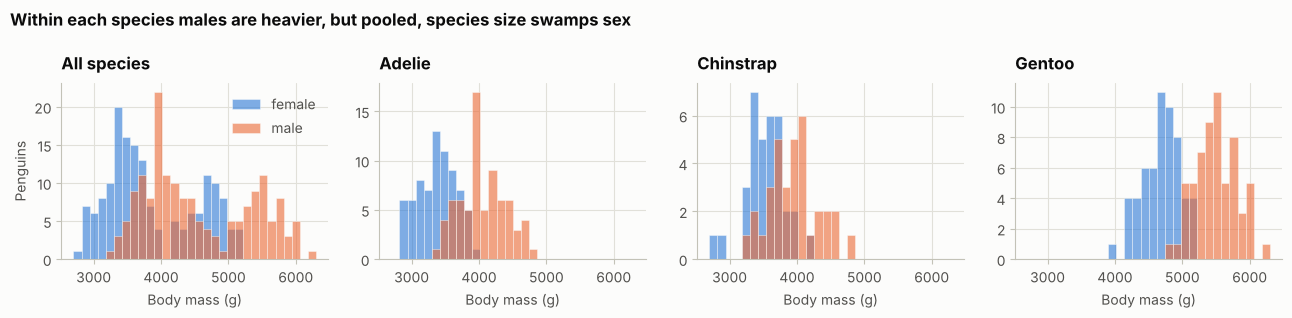

In [3]:
edges = np.linspace(2700, 6300, 31)
groups = [("All species", penguins)] + [(sp, penguins[penguins["species"] == sp]) for sp in SPECIES]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharex=True)
for ax, (name, data) in zip(axes, groups):
    for sex, colour in SEX_COLOURS.items():
        ax.hist(data.loc[data["sex"] == sex, "body_mass_g"], bins=edges, color=colour, alpha=0.6,
                edgecolor=SURFACE, linewidth=0.5, label=sex)
    ax.set_title(name)
    ax.set_xlabel("Body mass (g)")
axes[0].set_ylabel("Penguins")
axes[0].legend(loc="upper right")
fig.suptitle("Within each species males are heavier, but pooled, species size swamps sex",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Within each species, the two sexes are well separated by weight. Pooled together, they overlap heavily, because a typical female Gentoo is heavier than a typical male Adelie. Body mass mostly tells you the **species**.

So a good model needs either several measurements together, or the species as an extra input. We'll try both and let the test set decide in Step 7.

## Step 2: The model

Logistic regression turns a weighted sum of features into a probability:

$$z = Xw + b, \qquad p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

where `p` is the predicted probability that the penguin is male.

**The features** are the four measurements, standardised with the **training** set's mean and standard deviation, plus two 0/1 columns for the species (Chinstrap and Gentoo; Adelie is the baseline when both are 0). Standardising matters for gradient descent, as the lesson's stretched bowl showed.

In [4]:
mean = train[MEASUREMENTS].mean()
std = train[MEASUREMENTS].std(ddof=0)
FEATURE_NAMES = ["bill length", "bill depth", "flipper length", "body mass", "is Chinstrap", "is Gentoo"]


def design(data, columns=MEASUREMENTS, species=True):
    """Feature matrix: standardised measurements, optionally followed by species indicator columns."""
    X = ((data[columns] - mean[columns]) / std[columns]).to_numpy()
    if species:
        indicators = [(data["species"] == sp).to_numpy(float) for sp in ["Chinstrap", "Gentoo"]]
        X = np.column_stack([X] + indicators)
    return X


X_train, y_train = design(train), train["is_male"].to_numpy()
X_test, y_test = design(test), test["is_male"].to_numpy()
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print(f"after standardising, largest training mean {np.abs(X_train[:, :4].mean(axis=0)).max():.0e}, "
      f"standard deviations {X_train[:, :4].std(axis=0).round(6)}")

X_train: (252, 6)  X_test: (81, 6)
after standardising, largest training mean 1e-15, standard deviations [1. 1. 1. 1.]


**The loss** is the mean log loss (cross-entropy for two classes), in the stable form from exercise 11:

$$L = \frac{1}{n} \sum_i \left[ \log(1 + e^{z_i}) - y_i z_i \right]$$

**The gradient**, by the chain rule. For one example, `dL/dz = σ(z) - y`, because the derivative of `log(1 + e^z)` is exactly `σ(z)`. Then `dz/dw = x` and `dz/db = 1`, and averaging over examples gives:

$$\frac{\partial L}{\partial w} = \frac{1}{n} X^\top (p - y), \qquad \frac{\partial L}{\partial b} = \frac{1}{n} \sum_i (p_i - y_i)$$

In [5]:
def sigmoid(z):
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1 / (1 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1 + ez)
    return out


def loss_and_grad(w, b, X, y):
    z = X @ w + b
    loss = np.mean(np.logaddexp(0, z) - y * z)
    error = sigmoid(z) - y
    return float(loss), X.T @ error / len(y), float(np.mean(error))


loss0, gw0, gb0 = loss_and_grad(np.zeros(6), 0.0, X_train, y_train)
print(f"starting loss {loss0:.4f}, log(2) = {np.log(2):.4f}")

starting loss 0.6931, log(2) = 0.6931


The first sanity check is free. With all weights at zero, every prediction is 0.5, so the loss must be `log(2)`. It is.

## Step 3: Check 1, the gradient

Compare the formula's gradient with a numerical one (central differences, from the lesson) at a **random** point. Checking at zero isn't enough, because some mistakes happen to vanish there.

The **relative error** puts the difference on a scale that doesn't depend on how large the gradient is:

$$\text{relative error} = \frac{\| g_\text{formula} - g_\text{numerical} \|}{\| g_\text{formula} \| + \| g_\text{numerical} \|}$$

Rule of thumb: below 10<sup>-7</sup> is correct; above 10<sup>-3</sup> is a bug.

In [6]:
def numerical_grad(w, b, X, y, h=1e-5):
    params = np.append(w, b)
    grad = np.zeros_like(params)
    for i in range(params.size):
        step = np.zeros_like(params)
        step[i] = h
        plus = loss_and_grad((params + step)[:-1], (params + step)[-1], X, y)[0]
        minus = loss_and_grad((params - step)[:-1], (params - step)[-1], X, y)[0]
        grad[i] = (plus - minus) / (2 * h)
    return grad


def relative_error(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))


w_random, b_random = rng.normal(size=6), 0.3
_, gw, gb = loss_and_grad(w_random, b_random, X_train, y_train)
formula = np.append(gw, gb)
numerical = numerical_grad(w_random, b_random, X_train, y_train)

for name, f_val, n_val in zip(FEATURE_NAMES + ["bias"], formula, numerical):
    print(f"{name:>15}: formula {f_val:+.8f}   numerical {n_val:+.8f}")
print(f"\nrelative error: {relative_error(formula, numerical):.1e}")

    bill length: formula -0.05051509   numerical -0.05051509
     bill depth: formula -0.35042249   numerical -0.35042249
 flipper length: formula +0.08499713   numerical +0.08499713
      body mass: formula -0.01440712   numerical -0.01440712
   is Chinstrap: formula -0.02311843   numerical -0.02311843
      is Gentoo: formula +0.11925040   numerical +0.11925040
           bias: formula +0.04710845   numerical +0.04710845

relative error: 7.9e-12


Agreement to every digit shown, and a relative error around 10<sup>-11</sup>. But a check is only useful if it **fails** when something is wrong. Here are two realistic mistakes: forgetting to divide by `n`, and getting the sign of the error backwards (`y - p` instead of `p - y`):

In [7]:
def grad_forgot_n(w, b, X, y):
    error = sigmoid(X @ w + b) - y
    return np.append(X.T @ error, error.sum())


def grad_wrong_sign(w, b, X, y):
    error = y - sigmoid(X @ w + b)
    return np.append(X.T @ error / len(y), error.mean())


for name, broken in [("forgot to divide by n", grad_forgot_n), ("wrong sign", grad_wrong_sign)]:
    print(f"{name:>22}: relative error {relative_error(broken(w_random, b_random, X_train, y_train), numerical):.2f}")

 forgot to divide by n: relative error 0.99
            wrong sign: relative error 1.00


Both are caught immediately: the relative errors are close to 1, not 10<sup>-10</sup>. Neither bug would crash, and the wrong sign would even look like training for a moment, as it walks **uphill**. This takes seconds and should be run whenever a gradient is written by hand.

## Step 4: Training with gradient descent

The gradient is right, so now train. The learning rate is the one choice to make, so try a range of values, each for 300 epochs:

In [8]:
def train_gd(X, y, lr, epochs):
    w, b = np.zeros(X.shape[1]), 0.0
    losses = []
    for _ in range(epochs):
        loss, gw, gb = loss_and_grad(w, b, X, y)
        losses.append(loss)
        w, b = w - lr * gw, b - lr * gb
    return w, b, np.array(losses)


rates = [0.1, 1, 10, 40]
curves = {lr: train_gd(X_train, y_train, lr, 300)[2] for lr in rates}
for lr, losses in curves.items():
    print(f"lr={lr:<4}  loss after 10 epochs {losses[10]:.3f}, after 300 {losses[-1]:.3f}")

lr=0.1   loss after 10 epochs 0.594, after 300 0.281
lr=1     loss after 10 epochs 0.357, after 300 0.216
lr=10    loss after 10 epochs 0.233, after 300 0.190
lr=40    loss after 10 epochs 0.524, after 300 0.650


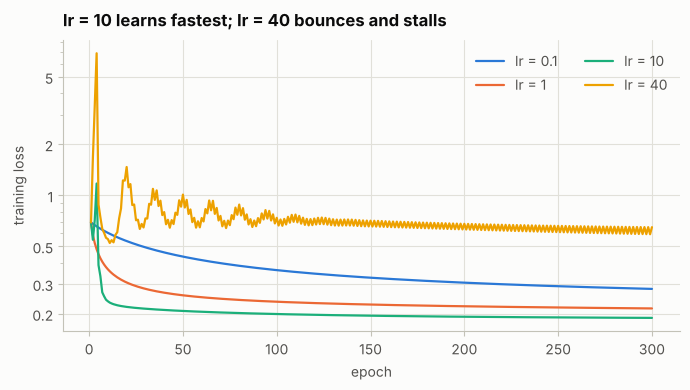

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for (lr, losses), colour in zip(curves.items(), PALETTE):
    ax.plot(np.arange(1, 301), losses, color=colour, label=f"lr = {lr}")
ax.set_yscale("log")
ax.set_yticks([0.2, 0.3, 0.5, 1, 2, 5])
ax.yaxis.set_major_formatter(plain)
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("epoch")
ax.set_ylabel("training loss")
ax.set_title("lr = 10 learns fastest; lr = 40 bounces and stalls")
ax.legend(loc="upper right", ncols=2)
fig.tight_layout()
plt.show()

The same pattern as the lesson's bowl:

- **0.1** is safe but slow: after 300 epochs it's still well above the others.
- **1** and **10** both work. 10 is fastest, after a brief spike in the first few epochs while the weights are still far from sensible values.
- **40** is too big. With log loss the weights don't explode to infinity as they did on the quadratic bowl, but the loss jumps around and stays high.

So `lr = 10` is the choice. That's large compared with the 0.001 you might see for neural networks, but learning rates aren't universal: they depend on the scale of the loss surface. With standardised features and a loss averaged over examples, values around 1 to 10 are typical for logistic regression.

## Step 5: Check 2, the optimum

The log loss for logistic regression is **convex**: it has a single minimum, with no other valleys to get stuck in. That means any correct training method must end up at the same weights. So train a second way and compare.

**Newton's method** uses the curvature (second derivatives) as well as the slope. Instead of a fixed step size, it solves for the step that would land exactly at the minimum if the loss were a perfect bowl:

$$\theta \leftarrow \theta - H^{-1} \nabla L, \qquad H = \frac{1}{n} X^\top \operatorname{diag}\big(p(1 - p)\big) X$$

`H` is the **Hessian**, the matrix of second derivatives. The bias is handled by adding a column of ones to `X`, so `θ` holds the weights followed by the bias. Following section 2 of the lesson, the step is computed with `np.linalg.solve`, not an inverse.

In [10]:
def train_newton(X, y, iterations=12):
    A = np.column_stack([X, np.ones(len(X))])
    theta = np.zeros(A.shape[1])
    history = []
    for _ in range(iterations):
        p = sigmoid(A @ theta)
        grad = A.T @ (p - y) / len(y)
        hessian = A.T @ (A * (p * (1 - p))[:, None]) / len(y)
        theta = theta - np.linalg.solve(hessian, grad)
        history.append(theta.copy())
    return theta, np.array(history)


theta_newton, newton_history = train_newton(X_train, y_train)
w_gd, b_gd, gd_losses = train_gd(X_train, y_train, lr=10, epochs=20_000)
theta_gd = np.append(w_gd, b_gd)

print(f"{'':>15}  {'Newton':>9}  {'grad. descent':>13}")
for name, a, b in zip(FEATURE_NAMES + ["bias"], theta_newton, theta_gd):
    print(f"{name:>15}  {a:+9.4f}  {b:+13.4f}")
print(f"\nlargest difference: {np.abs(theta_newton - theta_gd).max():.1e}")

                    Newton  grad. descent
    bill length    +3.3600        +3.3600
     bill depth    +2.9488        +2.9488
 flipper length    +0.9747        +0.9747
      body mass    +4.9709        +4.9709
   is Chinstrap    -7.7376        -7.7376
      is Gentoo   -10.4486       -10.4486
           bias    +5.5834        +5.5834

largest difference: 3.1e-13


The same weights to about twelve decimal places, found by two completely different methods. That's strong evidence that both the loss and the gradient are right, and that training really reached the minimum.

But look at the cost. Newton's method took 12 iterations; gradient descent took 20,000 epochs. Here's how quickly each one closes in on the answer:

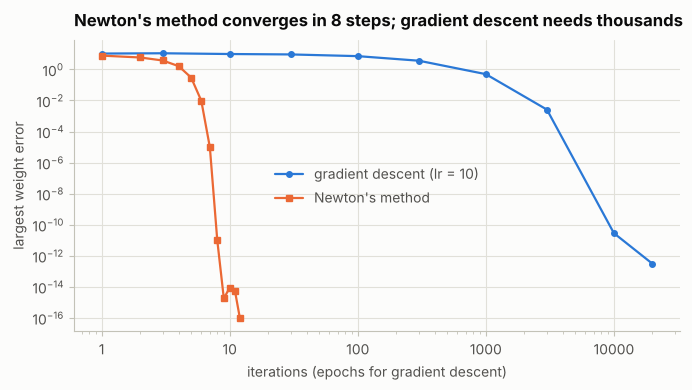

In [11]:
gd_check = [1, 3, 10, 30, 100, 300, 1000, 3000, 10_000, 20_000]
w, b = np.zeros(6), 0.0
gd_distance = []
for epoch in range(1, 20_001):
    _, gw, gb = loss_and_grad(w, b, X_train, y_train)
    w, b = w - 10 * gw, b - 10 * gb
    if epoch in gd_check:
        gd_distance.append(np.abs(np.append(w, b) - theta_newton).max())
newton_distance = np.abs(newton_history - theta_newton).max(axis=1)
newton_distance[newton_distance == 0] = 1e-16     # exactly zero can't go on a log axis

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(gd_check, gd_distance, color=PALETTE[0], marker="o", markersize=4, label="gradient descent (lr = 10)")
ax.plot(np.arange(1, len(newton_distance) + 1), newton_distance, color=PALETTE[1], marker="s", markersize=4,
        label="Newton's method")
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(plain)
ax.set_xlabel("iterations (epochs for gradient descent)")
ax.set_ylabel("largest weight error")
ax.set_title("Newton's method converges in 8 steps; gradient descent needs thousands")
ax.legend(loc="center")
fig.tight_layout()
plt.show()

The two curves have different shapes:

- **Gradient descent** spends the first few hundred epochs barely moving, then steadily gains digits, reaching 10<sup>-10</sup> after 10,000 epochs. The slow start comes from the features being correlated with each other and with species, which makes the loss surface a long, narrow valley.
- **Newton's method** roughly **doubles the number of correct digits** each step once it's close: from 10<sup>-2</sup> to 10<sup>-5</sup> to 10<sup>-11</sup>.

So why isn't Newton's method used for everything? Each step solves a system with a `d × d` Hessian. With 7 parameters that's instant. A neural network with 100 million parameters would need a Hessian with 10<sup>16</sup> entries. That's why deep learning uses gradient descent and its variants, and why the curvature problem is attacked indirectly, with standardisation, normalisation layers and optimisers like Adam.

## Step 6: Reading the model

Because the measurements are standardised, each weight is the change in **log-odds** of being male for a one standard deviation increase in that measurement, with the others held fixed. `exp(weight)` turns it into an **odds ratio**.

How sure are we about each weight? The bootstrap from the lesson: resample the **training** penguins with replacement, refit, and repeat. Newton's method makes each refit instant.

In [12]:
n_boot = 1000
boot_thetas = np.empty((n_boot, 7))
for i in range(n_boot):
    rows = rng.integers(0, len(X_train), size=len(X_train))
    boot_thetas[i] = train_newton(X_train[rows], y_train[rows], iterations=15)[0]

low, high = np.percentile(boot_thetas, [2.5, 97.5], axis=0)
summary = pd.DataFrame({
    "weight": theta_newton[:6],
    "ci_low": low[:6],
    "ci_high": high[:6],
}, index=FEATURE_NAMES).round(2)
summary

,weight,ci_low,ci_high
bill length,3.36,1.94,7.48
bill depth,2.95,1.37,6.21
flipper length,0.97,-1.43,3.17
body mass,4.97,3.83,9.23
is Chinstrap,-7.74,-16.70,-4.58
is Gentoo,-10.45,-19.20,-6.94


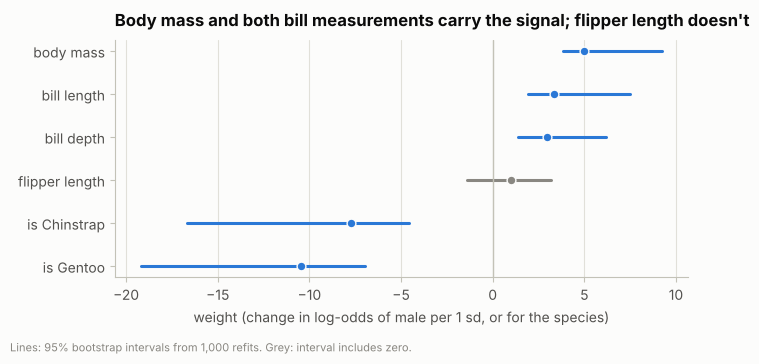

In [13]:
order = np.argsort(theta_newton[:6])
fig, ax = plt.subplots(figsize=(7, 3.6))
for row, i in enumerate(order):
    crosses_zero = low[i] < 0 < high[i]
    colour = MUTED if crosses_zero else PALETTE[0]
    ax.plot([low[i], high[i]], [row, row], color=colour, linewidth=2.2, solid_capstyle="round")
    ax.scatter([theta_newton[i]], [row], color=colour, s=40, zorder=3, edgecolors=SURFACE, linewidths=1)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(range(6), [FEATURE_NAMES[i] for i in order])
ax.grid(axis="y", visible=False)
ax.set_xlabel("weight (change in log-odds of male per 1 sd, or for the species)")
ax.set_title("Body mass and both bill measurements carry the signal; flipper length doesn't")
fig.text(0.01, 0.01, "Lines: 95% bootstrap intervals from 1,000 refits. Grey: interval includes zero.",
         color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

What the model says:

- **Body mass, bill depth and bill length** all have clearly positive weights: within a species, bigger penguins with deeper, longer bills are more likely to be male. Body mass has the largest weight, about 5. As an odds ratio, `exp(5) ≈ 150`: one standard deviation more mass (about 800 g) multiplies the odds of male by around 150, with the other measurements and species held fixed. That's very large, which says how strongly mass separates the sexes **within** a species.
- **Flipper length's** interval includes zero. Once the other measurements are known, flipper length adds nothing reliable.
- **The species weights** are large and negative. That doesn't mean Gentoos are less likely to be male. It means that **for the same measurements**, a Gentoo is less likely to be male, because a Gentoo of a given size is small for a Gentoo. This is Step 1's lesson inside the model: the species columns let it judge size relative to the species.

Two cautions. The intervals are wide and lopsided: body mass's runs from about 4 to 9. Some bootstrap resamples are close to perfectly separable, and when that happens logistic regression's weights grow large, which stretches the upper ends. And the measurements are correlated, so the weights share credit between them: drop one feature and the others would change. Weights describe this model, not the biology directly.

## Step 7: Check 3, the result

Now, once, the test set. Four models, from simplest to the full one:

In [14]:
def fit_and_score(columns, species):
    Xa, Xb = design(train, columns, species), design(test, columns, species)
    theta = train_newton(Xa, y_train, iterations=15)[0]
    p = sigmoid(np.column_stack([Xb, np.ones(len(Xb))]) @ theta)
    return (p > 0.5) == y_test                     # one True/False per test penguin


correct = {
    "always 'male'": (y_test == 1),
    "body mass only": fit_and_score(["body_mass_g"], species=False),
    "4 measurements": fit_and_score(MEASUREMENTS, species=False),
    "4 measurements + species": fit_and_score(MEASUREMENTS, species=True),
}


def bootstrap_accuracy(hits, n_boot=5000):
    picks = rng.integers(0, len(hits), size=(n_boot, len(hits)))
    return np.percentile(hits[picks].mean(axis=1), [2.5, 97.5])


results = pd.DataFrame(
    [(hits.mean(), *bootstrap_accuracy(hits), hits.sum()) for hits in correct.values()],
    index=correct.keys(), columns=["accuracy", "ci_low", "ci_high", "correct"],
)
results["correct"] = results["correct"].astype(int)
results.round(3)

,accuracy,ci_low,ci_high,correct
always 'male',0.506,0.395,0.617,41
body mass only,0.580,0.469,0.679,47
4 measurements,0.889,0.815,0.951,72
4 measurements + species,0.914,0.852,0.975,74


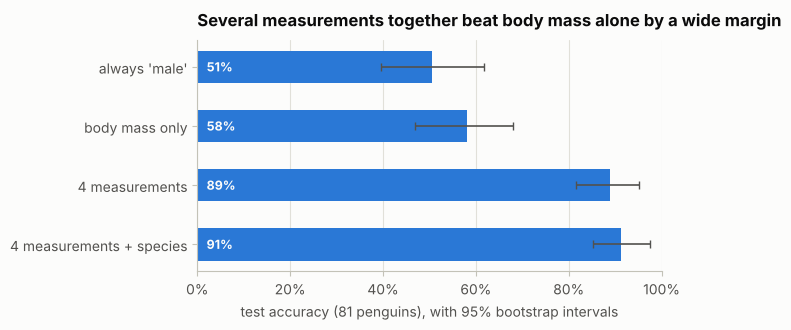

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.4))
labels = list(results.index)[::-1]
values = results["accuracy"].to_numpy()[::-1]
errors = np.abs(results[["ci_low", "ci_high"]].to_numpy()[::-1].T - values)
ax.barh(labels, values, color=PALETTE[0], height=0.55)
ax.errorbar(values, labels, xerr=errors, fmt="none", ecolor=INK_2, elinewidth=1.2, capsize=3)
for row, v in enumerate(values):
    ax.text(0.02, row, f"{v:.0%}", va="center", color=SURFACE, fontsize=9, fontweight="bold")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"test accuracy ({len(y_test)} penguins), with 95% bootstrap intervals")
ax.set_title("Several measurements together beat body mass alone by a wide margin")
fig.tight_layout()
plt.show()

The baselines put the result in context:

- Always guessing "male" gets about half right, as expected.
- **Body mass alone is barely better than guessing**, as Step 1 predicted.
- **All four measurements** jump to around 89%, and adding **species** reaches about 91%.

The intervals are the important part. With 81 test penguins, each one is worth 1.2 percentage points, and the 95% interval on the full model spans roughly 85% to 97%. The full model's interval also overlaps heavily with the measurements-only model's.

So is adding species really better, or just lucky on this test set? The models were tested on the **same** penguins, so compare them penguin by penguin. Most penguins are classified the same way by both; only the ones where they **disagree** carry information. The paired version of the permutation test: if the models were equally good, which model got each disagreement right would be a coin flip, so randomly swap the two models' results for each penguin and see how often the difference is as large as the real one.

In [16]:
full, simpler = correct["4 measurements + species"], correct["4 measurements"]
diff = full.astype(int) - simpler.astype(int)          # +1: only the full model right, -1: only the simpler one
observed = diff.sum()
print(f"penguins where the models disagree: {np.count_nonzero(diff)}")
print(f"  full model right, simpler wrong:  {np.sum(diff == 1)}")
print(f"  simpler right, full model wrong:  {np.sum(diff == -1)}")

n_perm = 20_000
signs = rng.choice([-1, 1], size=(n_perm, len(diff)))
shuffled = (signs * diff).sum(axis=1)
p_value = (np.sum(np.abs(shuffled) >= abs(observed)) + 1) / (n_perm + 1)
print(f"\nnet difference: {observed:+d} penguins, p = {p_value:.2f}")

penguins where the models disagree: 2
  full model right, simpler wrong:  2
  simpler right, full model wrong:  0

net difference: +2 penguins, p = 0.50


**No evidence that adding species helps on this test set.** The two models disagree on just 2 penguins, and the full model got both. If the models were equally good, that's like two coin flips landing the same way, which happens half the time: p = 0.5. The higher accuracy might be real, but 81 penguins can't show it.

That's not a disappointing result; it's an honest one. Two things would settle it: more test data, or cross-validation (which uses every penguin for testing once). Module 10's engineering practices make that kind of repeated evaluation easy to set up.

## Summary

| Check | What it tested | Result |
|---|---|---|
| Starting loss | loss is computed correctly | exactly `log(2)` with zero weights |
| Gradient check | the hand-derived gradient | relative error about 10<sup>-11</sup>, and two planted bugs both caught |
| Two optimisers | training reaches the true minimum | Newton and gradient descent agree to about 12 decimal places |
| Bootstrap weights | which features matter | body mass, bill depth and bill length clearly positive; flipper length not distinguishable from zero |
| Test accuracy | the final model | about 91% (95% interval roughly 85% to 97%), against 51% for always guessing male and 58% for body mass alone |
| Paired permutation test | whether species helps | no evidence: the models disagree on only 2 of 81 test penguins |

What carries over to any model you build:

- **A wrong gradient doesn't crash.** Check it numerically, at a random point, and make sure the check fails on a planted bug.
- **When an independent route to the answer exists, use it.** Two methods agreeing is far stronger evidence than one method looking reasonable.
- **Curvature decides speed.** Correlated or unscaled features make gradient descent crawl; that's the practical reason for standardising.
- **Every number from data needs an interval.** A one-penguin difference on a small test set is noise until proven otherwise, and comparisons between models should be paired.

**Ideas to extend it:**

- Use 5-fold cross-validation to get a more precise comparison between the two best models.
- Add an **L2 penalty** `λ‖w‖²/2` to the loss. Update the gradient and Hessian, re-run the gradient check, and watch what happens to the large species weights.
- Plot a **calibration curve**: group test penguins by predicted probability and compare with the fraction that are actually male.